In [2]:
import csv
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
import umap
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
from scipy.stats import chi2_contingency
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_ind
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_auc_score, RocCurveDisplay

# Part 1

In [3]:
#  laod expression data

expr_df = pd.read_csv("data/GSE40419_LC-87_RPKM_expression.txt", sep='\t', index_col=0, dtype={'chrom': str})
display(expr_df.head())


# load sample metadata

sample_data = {}

with open("data/GSE40419_series_matrix.txt", encoding="utf-8-sig") as file:
    for line in file:
        values = line.strip().replace('"', "").split("\t")

        if values[0] == "!Sample_title":
            sample_data["sample"] = values[1:]

        elif values[0] == "!Sample_characteristics_ch1":
            field = values[1].split(":", 1)[0].strip()

            if field in ("gender", "smoking_status"):
                cleaned_values = []
                for value in values[1:]:
                    cleaned_values.append(value.split(":", 1)[1].strip())

                sample_data[field] = cleaned_values

metadata = pd.DataFrame(sample_data)
metadata = metadata.rename(columns={
    "gender": "sex",
    "smoking_status": "smoking"
})
metadata["smoking"] = metadata["smoking"].replace("NA", pd.NA)
metadata["patient"] = metadata["sample"].str.replace(r"_nor$", "", regex=True)

display(metadata.head())

,accession,chrom,start,end,strand,LC_C1,LC_C2,LC_C3,LC_C4,LC_C5,...,LC_S48_nor,LC_S49_nor,LC_S1_nor,LC_S2_nor,LC_S3_nor,LC_S4_nor,LC_S5_nor,LC_S50_nor,LC_S51_nor,LC_S52_nor
gene,,,,,,,,,,,,,,,,,,,,,
WASH7P,NR_024540,1,14361,29370,-,1.83,2.13,4.26,3.26,1.43,...,2.60,5.04,2.49,2.63,3.71,2.1,2.82,2.30,2.62,3.98
FAM138A,NR_026818,1,34610,36081,-,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00
FAM138F,NR_026820,1,34610,36081,-,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00
OR4F5,NM_001005484,1,69090,70008,+,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00
LOC100132287,NR_028322,1,323891,328581,+,0.05,0.02,0.04,0.00,0.02,...,0.01,0.02,0.01,0.00,0.04,0.0,0.03,0.04,0.00,0.04


,sample,sex,smoking,patient
0,LC_C1,male,smoker,LC_C1
1,LC_C2,male,current smoker,LC_C2
2,LC_C3,female,never smoker,LC_C3
3,LC_C4,male,never smoker,LC_C4
4,LC_C5,male,NaN,LC_C5


In [4]:
# Apply log2(RPKM + 1) transformation
expr_df.iloc[:, 5:] = np.log2(expr_df.iloc[:, 5:].astype(float) + 1)

# Filter genes: keep those with RPKM >= 1 in at least 10% of samples
expression = expr_df.iloc[:, 5:]

genes_before = len(expr_df)

# log2(RPKM + 1) >= 1 is equivalent to RPKM >= 1
expressed_fraction = (expression >= 1).mean(axis=1)

expr_df = expr_df.loc[expressed_fraction >= 0.10].copy()

genes_removed = genes_before - len(expr_df)
removed_percent = 100 * genes_removed / genes_before

print("Genes removed:", genes_removed)
print(f"Percentage removed: {removed_percent:.2f}%")
print("Genes remaining:", len(expr_df))

Genes removed: 9552
Percentage removed: 26.00%
Genes remaining: 27190


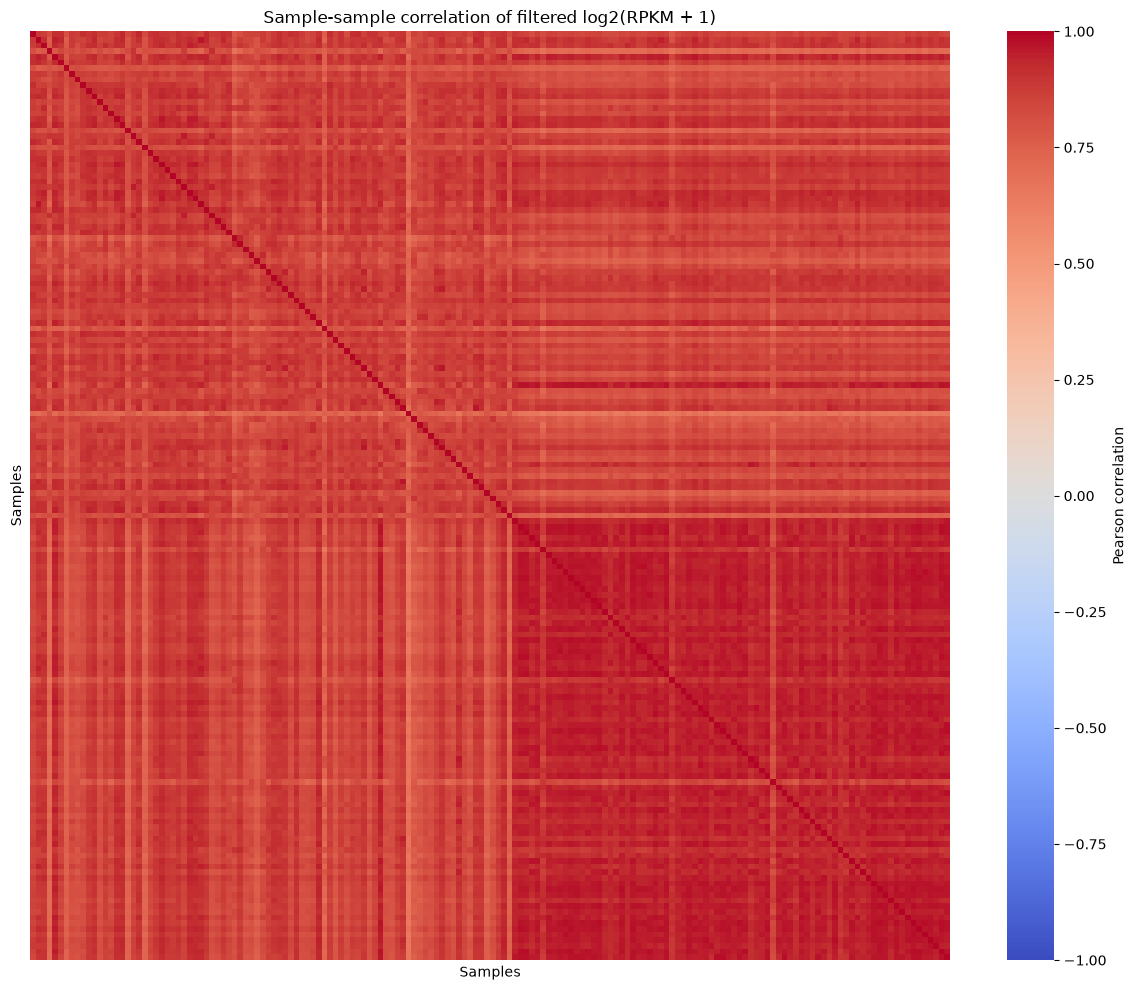

In [5]:
# Visualize sample-sample correlation

expression = expr_df.iloc[:, 5:]
sample_correlations = expression.corr(method="pearson")

plt.figure(figsize=(12, 10))
sns.heatmap(
    sample_correlations,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={"label": "Pearson correlation"}
)
plt.title("Sample-sample correlation of filtered log2(RPKM + 1)")
plt.xlabel("Samples")
plt.ylabel("Samples")
plt.tight_layout()
plt.show()

All samples show positive correlations of their gene expression proifles. There is a clear region of higher correlation between non-cancerous samples. One possible cause is greater variation of genetic material in cancerous cells.

# Part 2

In [6]:
# Remove the five annotation columns, then transpose.
X = expr_df.iloc[:, 5:].T.copy()

# Give each expression record a unique feature label.
X.columns = range(X.shape[1])

display(X.head())

# Align metadata with the sample order in X.
labels = metadata.set_index("sample").loc[X.index].copy()

labels["tissue"] = "Tumour"
labels.loc[labels.index.str.endswith("_nor"), "tissue"] = "Normal"

labels["sex"] = labels["sex"].fillna("Unavailable")
labels["smoking"] = labels["smoking"].fillna("Unavailable")

display(labels)

,0,1,2,3,4,5,6,7,8,9,...,27180,27181,27182,27183,27184,27185,27186,27187,27188,27189
LC_C1,1.500802,1.744161,1.967169,1.550901,2.477677,0.622930,2.330558,4.593354,1.929791,1.773996,...,0.807355,0.400538,0.042644,8.667786,1.839960,2.599318,3.390943,3.440952,3.459432,2.954196
LC_C2,1.646163,1.867896,1.735522,1.906891,1.891419,0.903038,1.510962,4.023255,1.490570,0.985500,...,0.678072,1.565597,0.584963,6.859473,3.104337,3.752749,4.524816,4.571070,4.607034,4.053111
LC_C3,2.395063,1.084064,0.238787,1.304511,1.933573,0.495695,2.269033,4.267536,1.883621,0.687061,...,0.000000,0.000000,0.000000,7.212764,0.000000,0.014355,0.028569,0.028569,0.028569,0.014355
LC_C4,2.090853,1.687061,1.704872,2.140779,1.891419,0.356144,2.090853,5.475085,1.879706,1.117695,...,0.070389,0.757023,0.367371,9.402905,3.063503,3.835924,3.561937,3.601697,3.621759,3.811471
LC_C5,1.280956,1.257011,1.189034,1.669027,3.121015,0.454176,2.211012,4.389567,1.757023,1.028569,...,0.782409,1.344828,0.713696,5.993221,2.643856,3.689299,4.182692,4.234195,4.245648,4.291309


,sex,smoking,patient,tissue
sample,,,,
LC_C1,male,smoker,LC_C1,Tumour
LC_C2,male,current smoker,LC_C2,Tumour
LC_C3,female,never smoker,LC_C3,Tumour
LC_C4,male,never smoker,LC_C4,Tumour
LC_C5,male,Unavailable,LC_C5,Tumour
...,...,...,...,...
LC_S4_nor,male,never smoker,LC_S4,Normal
LC_S5_nor,male,smoker,LC_S5,Normal
LC_S50_nor,female,never smoker,LC_S50,Normal


In [7]:
pca = PCA(n_components=2)
pca_coordinates = pca.fit_transform(X)

tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42
)
tsne_coordinates = tsne.fit_transform(X)

umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)
umap_coordinates = umap_model.fit_transform(X)

d:\Studiowe\DataScience\Sem 1\Bioinformatics\Projekt 1\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
d:\Studiowe\DataScience\Sem 1\Bioinformatics\Projekt 1\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


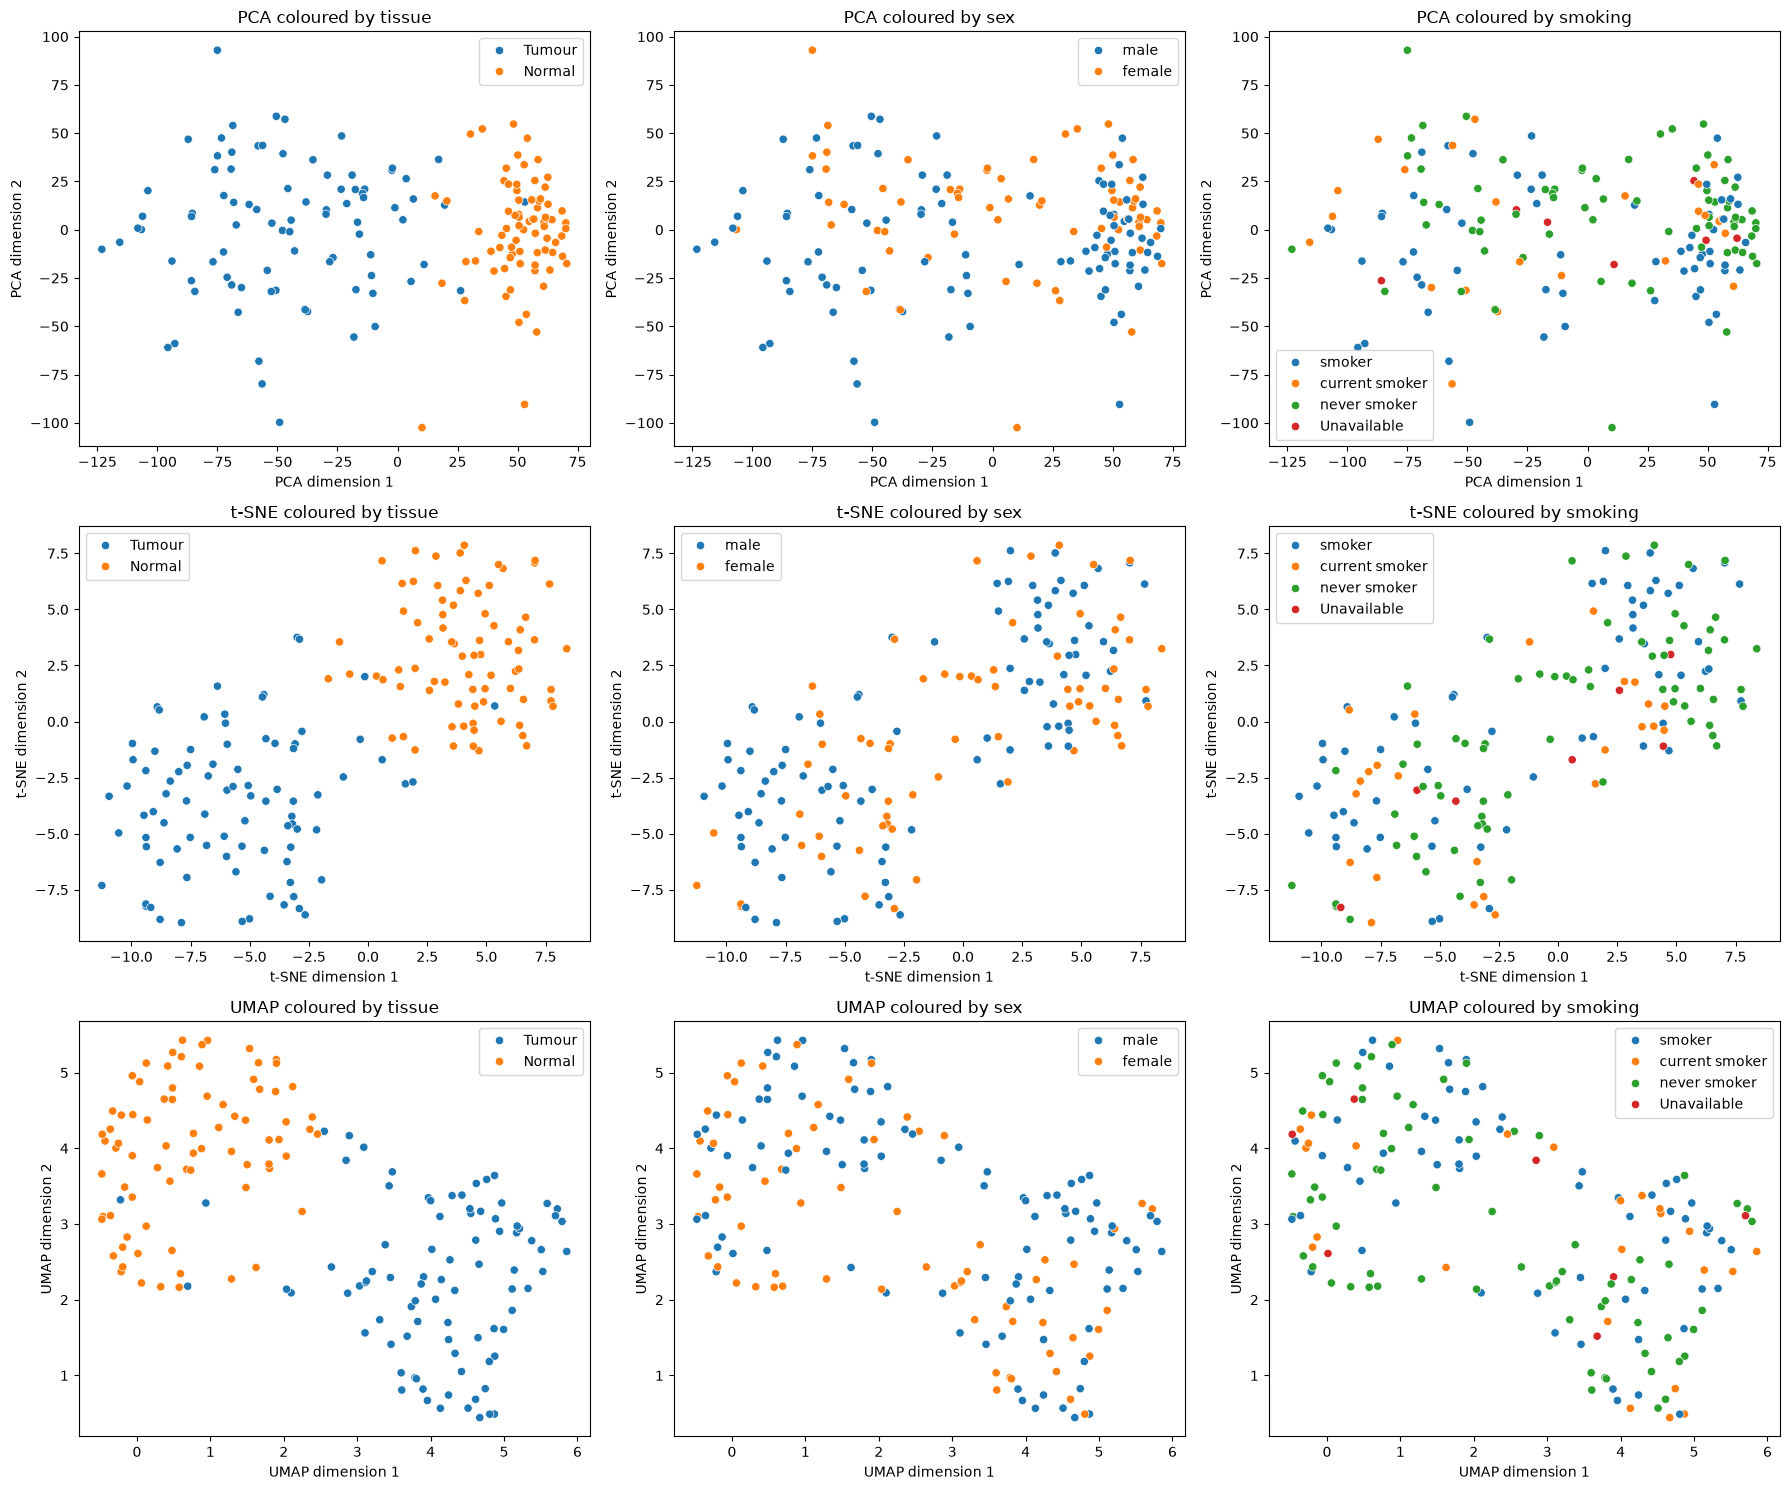

In [8]:
embeddings = {
    "PCA": pca_coordinates,
    "t-SNE": tsne_coordinates,
    "UMAP": umap_coordinates
}

variables = ["tissue", "sex", "smoking"]

fig, axes = plt.subplots(3, 3, figsize=(18, 15))

for row, (method, coordinates) in enumerate(embeddings.items()):
    for column, variable in enumerate(variables):
        ax = axes[row, column]

        sns.scatterplot(
            x=coordinates[:, 0],
            y=coordinates[:, 1],
            hue=labels[variable].to_numpy(),
            ax=ax
        )

        ax.set_title(f"{method} coloured by {variable}")
        ax.set_xlabel(f"{method} dimension 1")
        ax.set_ylabel(f"{method} dimension 2")

plt.tight_layout()
plt.show()

All dimensionality reduction techniques show a clear separation between different tissue types. Meanwhile the sex and smoking status are not clearly separated in any of the methods.

In [9]:
embeddings = {
    "PCA": pca_coordinates,
    "t-SNE": tsne_coordinates,
    "UMAP": umap_coordinates
}

for method, coordinates in embeddings.items():
    score = silhouette_score(coordinates, labels["tissue"])
    print(f"{method}: {score:.3f}")

PCA: 0.500
t-SNE: 0.564
UMAP: 0.548


# Part 3

In [10]:
# k means and hierarchical clustering for all samples

kmeans = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
)
kmeans_labels = kmeans.fit_predict(X)

hierarchical = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)
hierarchical_labels = hierarchical.fit_predict(X)

cluster_results = labels.copy()
cluster_results["kmeans_cluster"] = kmeans_labels
cluster_results["hierarchical_cluster"] = hierarchical_labels

kmeans_ari = adjusted_rand_score(labels["tissue"], kmeans_labels)
hierarchical_ari = adjusted_rand_score(labels["tissue"], hierarchical_labels)

print(f"K-means ARI: {kmeans_ari:.3f}")
print(f"Hierarchical clustering ARI: {hierarchical_ari:.3f}")

K-means ARI: 0.791
Hierarchical clustering ARI: 0.813


In [11]:
# tumors only clustering 

# Select tumour samples.
tumour_mask = labels["tissue"] == "Tumour"
X_tumour = X.loc[tumour_mask]
tumour_results = labels.loc[tumour_mask].copy()

# Fit both clustering methods again using tumour samples only.
tumour_results["kmeans_cluster"] = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
).fit_predict(X_tumour)

tumour_results["hierarchical_cluster"] = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
).fit_predict(X_tumour)

# Exclude unknown smoking status from association tests.
known_smoking = tumour_results["smoking"].notna()
known_smoking &= tumour_results["smoking"] != "Unavailable"
association_data = tumour_results.loc[known_smoking]

rng = np.random.default_rng(42)
n_permutations = 500
test_results = []

for method in ["kmeans_cluster", "hierarchical_cluster"]:
    table = pd.crosstab(
        association_data[method],
        association_data["smoking"]
    )

    print(f"\n{method}:")
    print(table)

    if table.shape[0] < 2 or table.shape[1] < 2:
        print("Insufficient categories to test association.")
        continue

    observed_statistic = chi2_contingency(table, correction=False).statistic

    # Shuffle smoking labels to simulate no association with clusters.
    smoking = association_data["smoking"].to_numpy()
    cluster_ids = association_data[method].to_numpy()
    extreme_count = 0

    for permutation in range(n_permutations):
        shuffled_smoking = rng.permutation(smoking)
        shuffled_table = pd.crosstab(cluster_ids, shuffled_smoking)

        statistic = chi2_contingency(
            shuffled_table, correction=False
        ).statistic

        if statistic >= observed_statistic:
            extreme_count += 1

    p_value = (extreme_count + 1) / (n_permutations + 1)

    test_results.append({
        "method": method,
        "samples_tested": len(association_data),
        "permutation_p": p_value
    })

association_results = pd.DataFrame(test_results)

# Bonferroni correction for the two clustering-method comparisons.
association_results["adjusted_p"] = (
    association_results["permutation_p"] * len(association_results)
).clip(upper=1)

display(association_results)



kmeans_cluster:
smoking         current smoker  never smoker  smoker
kmeans_cluster                                      
0                            8            25      15
1                            7            11      17

hierarchical_cluster:
smoking               current smoker  never smoker  smoker
hierarchical_cluster                                      
0                                  6            32      15
1                                  9             4      17


,method,samples_tested,permutation_p,adjusted_p
0,kmeans_cluster,83,0.167665,0.335329
1,hierarchical_cluster,83,0.001996,0.003992


Hierarchical clustering proves a statistical significance of cancer being assosiated with smoking. In case of k-means we recieve no statistical significance.

# Part 4

In [12]:
# Load GSE10072 expression and metadata.
series_path = "data/GSE10072_series_matrix.txt"
expression_10072 = pd.read_csv(
    series_path, sep="\t", comment="!", index_col=0
)

field_names = {
    "!Sample_geo_accession": "sample",
    "!Sample_title": "title",
    "!Sample_source_name_ch1": "tissue",
    "Gender": "sex",
    "Cigarette Smoking Status": "smoking"
}
sample_data = {}

with open(series_path, encoding="utf-8-sig", newline="") as file:
    for row in csv.reader(file, delimiter="\t"):
        if not row:
            continue

        field = row[0]
        values = row[1:]

        if field == "!Sample_characteristics_ch1":
            field = values[0].split(":", 1)[0].strip()
            if field not in field_names:
                continue

            cleaned_values = []
            for value in values:
                cleaned_values.append(value.split(":", 1)[1].strip())
            values = cleaned_values

        if field in field_names:
            sample_data[field_names[field]] = values

metadata_10072 = pd.DataFrame(sample_data).set_index("sample")
metadata_10072["tissue"] = metadata_10072["tissue"].replace({
    "Adenocarcinoma of the Lung": "Tumour",
    "Normal Lung Tissue": "Normal"
})
# Candidate patient identifier, not independently verified.
metadata_10072["patient"] = metadata_10072["title"].str.extract(
    r"(GT\d+)$", expand=False
)
metadata_10072 = metadata_10072.loc[expression_10072.columns]

display(expression_10072.head())
display(metadata_10072.head())


,GSM254625,GSM254626,GSM254627,GSM254628,GSM254629,GSM254630,GSM254631,GSM254632,GSM254633,GSM254634,...,GSM254722,GSM254723,GSM254724,GSM254725,GSM254726,GSM254727,GSM254728,GSM254729,GSM254730,GSM254731
ID_REF,,,,,,,,,,,,,,,,,,,,,
1007_s_at,10.927084,10.416978,10.628538,10.151180,10.988512,10.778205,10.568814,10.479425,10.548843,10.465005,...,10.727493,10.740353,10.527962,10.193615,10.768815,10.467693,10.902778,10.869402,10.292285,10.407218
1053_at,6.895217,6.924856,7.550245,6.699557,6.826031,6.718372,6.739765,6.724615,7.102475,6.627922,...,6.856575,6.737879,6.959032,7.008578,6.740444,6.795750,6.838162,6.628363,6.794050,6.358410
117_at,8.110190,7.760228,7.974676,7.712676,7.775592,7.777087,7.893210,8.058398,8.005438,7.961476,...,7.741922,7.805107,8.093078,8.144760,8.159483,7.855457,8.010428,7.889019,8.163266,7.973844
121_at,9.451286,9.520943,9.807597,9.522087,9.855061,9.861055,10.126183,9.878970,10.110318,10.411478,...,10.089149,10.007059,9.832610,10.107004,9.790645,9.645239,9.871851,9.867988,9.824801,9.850144
1255_g_at,4.814477,4.718640,4.905163,4.818076,4.823958,4.848313,5.125956,5.037979,4.889936,5.177818,...,5.048391,4.758050,4.900470,4.948760,4.609322,4.759571,4.788774,4.967626,4.817474,5.128892


,title,tissue,sex,smoking,patient
sample,,,,,
GSM254625,Lung Tumor_GT00006,Tumour,Male,Never Smoked,GT00006
GSM254626,Normal Lung_GT00006,Normal,Male,Never Smoked,GT00006
GSM254627,Lung Tumor_GT00007,Tumour,Male,Former Smoker,GT00007
GSM254628,Normal Lung_GT00007,Normal,Male,Former Smoker,GT00007
GSM254629,Lung Tumor_GT00022,Tumour,Female,Never Smoked,GT00022


In [13]:
# Identify candidate tumour-normal pairs based on sample names

tumours = metadata.loc[
    ~metadata["sample"].str.endswith("_nor")
].copy()

normals = metadata.loc[
    metadata["sample"].str.endswith("_nor")
].copy()

candidate_pairs = tumours.merge(
    normals,
    on="patient",
    suffixes=("_tumour", "_normal"),
    validate="one_to_one"
)

print("Candidate pairs:", len(candidate_pairs))

display(candidate_pairs[
    [
        "patient",
        "sample_tumour",
        "sample_normal",
        "sex_tumour",
        "sex_normal",
        "smoking_tumour",
        "smoking_normal"
    ]
])

Candidate pairs: 77


,patient,sample_tumour,sample_normal,sex_tumour,sex_normal,smoking_tumour,smoking_normal
0,LC_C1,LC_C1,LC_C1_nor,male,male,smoker,smoker
1,LC_C2,LC_C2,LC_C2_nor,male,male,current smoker,current smoker
2,LC_C3,LC_C3,LC_C3_nor,female,female,never smoker,never smoker
3,LC_C5,LC_C5,LC_C5_nor,male,male,NaN,NaN
4,LC_C7,LC_C7,LC_C7_nor,male,male,smoker,smoker
...,...,...,...,...,...,...,...
72,LC_S48,LC_S48,LC_S48_nor,female,female,never smoker,never smoker
73,LC_S49,LC_S49,LC_S49_nor,female,female,never smoker,never smoker
74,LC_S50,LC_S50,LC_S50_nor,female,female,never smoker,never smoker
75,LC_S51,LC_S51,LC_S51_nor,male,male,current smoker,current smoker


In [14]:
# finding differentially expressed genes between tumour and normal samples

def make_de_table(index, difference, p_values):
    results = pd.DataFrame({
        "mean_log2_difference": difference,
        "p_value": p_values
    }, index=index)

    results["FDR"] = multipletests(
        results["p_value"], method="fdr_bh"
    )[1]

    results["significant"] = results["FDR"] < 0.05
    results["selected"] = (
        results["significant"]
        & (results["mean_log2_difference"].abs() >= 1)
    )
    return results


# Matching column positions represent the same candidate patient.
tumour_expression = expr_df[candidate_pairs["sample_tumour"]].to_numpy()
normal_expression = expr_df[candidate_pairs["sample_normal"]].to_numpy()

test = ttest_rel(tumour_expression, normal_expression, axis=1)
difference = (tumour_expression - normal_expression).mean(axis=1)

de_results = make_de_table(expr_df.index, difference, test.pvalue)
de_results.insert(0, "accession", expr_df["accession"].to_numpy())

print("Pairs used:", len(candidate_pairs))
display(de_results.sort_values("FDR").head(20))


Pairs used: 77


,accession,mean_log2_difference,p_value,FDR,significant,selected
gene,,,,,,
GPM6A,NM_201591,-2.702138,3.488092e-40,9.484123e-36,True,True
GPM6A,NM_201592,-2.861853,1.079783e-39,9.786431e-36,True,True
GPM6A,NM_005277,-2.829493,7.291898e-40,9.786431e-36,True,True
RADIL,NM_018059,-1.251265,1.065042e-36,7.239620e-33,True,True
CCBE1,NM_133459,-2.266637,5.283077e-36,2.872937e-32,True,True
STX11,NM_003764,-1.944452,6.381951e-35,2.892088e-31,True,True
SCUBE1,NM_173050,-1.749516,9.624908e-34,3.738589e-30,True,True
C13orf36,NM_203451,-1.901579,3.359589e-33,1.141840e-29,True,True
PDLIM2,NM_176871,-1.436329,1.151324e-32,3.478279e-29,True,True


In [15]:
# Reproduce Lab 3: Welch's t-test for unpaired tumour and normal samples.

expression_10072 = expression_10072.apply(pd.to_numeric, errors="coerce").dropna()
expression_10072 = expression_10072.loc[
    ~expression_10072.index.str.startswith("AFFX")
]

tumour_samples_10072 = metadata_10072.index[metadata_10072["tissue"] == "Tumour"]
normal_samples_10072 = metadata_10072.index[metadata_10072["tissue"] == "Normal"]

T = expression_10072[tumour_samples_10072].to_numpy()
N = expression_10072[normal_samples_10072].to_numpy()

# Welch's test reproduces Lab 3; it does not account for matched tissues.
test = ttest_ind(T, N, axis=1, equal_var=False)
difference = T.mean(axis=1) - N.mean(axis=1)

de_10072 = make_de_table(expression_10072.index, difference, test.pvalue)

print("Tumour samples:", len(tumour_samples_10072))
print("Normal samples:", len(normal_samples_10072))
display(de_10072.sort_values("FDR").head(20))


Tumour samples: 58
Normal samples: 49


,mean_log2_difference,p_value,FDR,significant,selected
ID_REF,,,,,
209074_s_at,-3.371799,6.641899e-44,1.475498e-39,True,True
204396_s_at,-2.388072,2.009124e-41,2.231635e-37,True,True
204677_at,-2.619573,1.317136e-40,9.753390e-37,True,True
208982_at,-1.813914,3.357325e-39,1.864574e-35,True,True
213103_at,-1.219820,5.221337e-39,2.319840e-35,True,True
208981_at,-1.688902,7.219182e-39,2.672902e-35,True,True
210081_at,-4.417470,4.769095e-38,1.513506e-34,True,True
202112_at,-2.258474,1.464679e-37,3.959895e-34,True,True
209875_s_at,4.364415,1.782532e-37,3.959895e-34,True,True


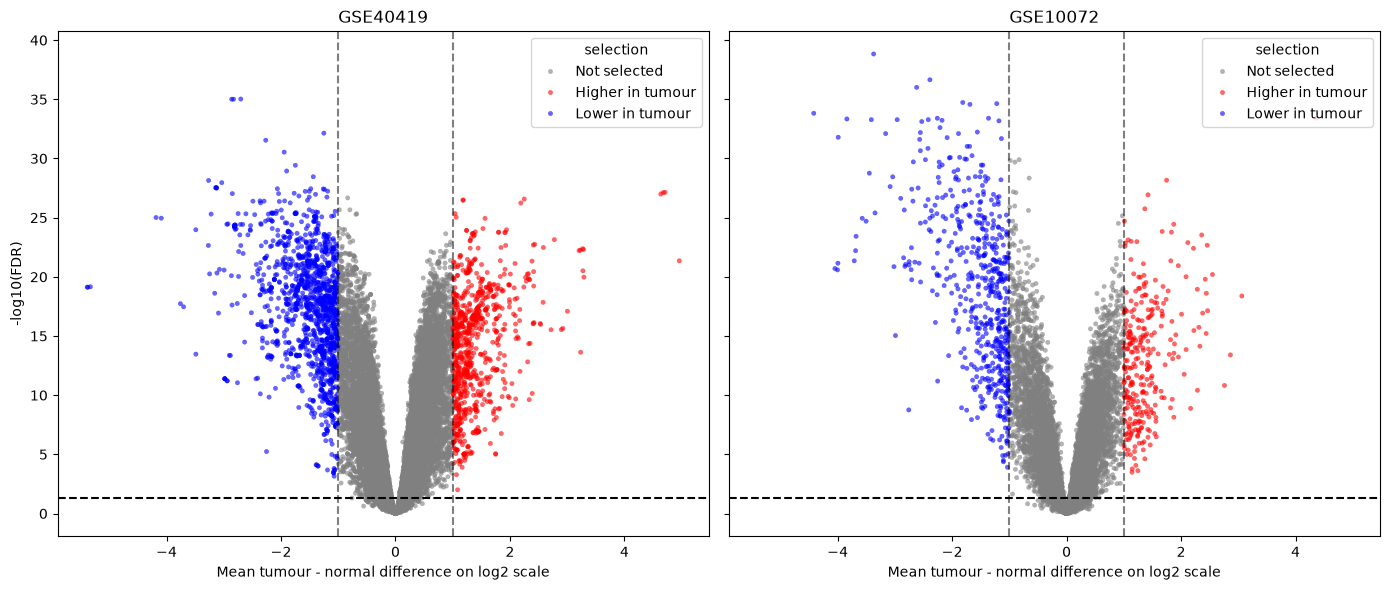

In [16]:
# plot both volcano plots side by side for GSE40419 and GSE10072

datasets = {"GSE40419": de_results, "GSE10072": de_10072}

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

for ax, (name, results) in zip(axes, datasets.items()):
    plot_data = results.dropna(subset=["mean_log2_difference", "FDR"]).copy()
    plot_data["minus_log10_FDR"] = -np.log10(
        plot_data["FDR"].clip(lower=np.finfo(float).tiny)
    )

    # "Not selected" includes significant records with small effects.
    plot_data["selection"] = "Not selected"
    plot_data.loc[
        plot_data["selected"] & (plot_data["mean_log2_difference"] > 0),
        "selection"
    ] = "Higher in tumour"
    plot_data.loc[
        plot_data["selected"] & (plot_data["mean_log2_difference"] < 0),
        "selection"
    ] = "Lower in tumour"

    sns.scatterplot(
        data=plot_data,
        x="mean_log2_difference",
        y="minus_log10_FDR",
        hue="selection",
        hue_order=["Not selected", "Higher in tumour", "Lower in tumour"],
        palette={
            "Not selected": "grey",
            "Higher in tumour": "red",
            "Lower in tumour": "blue"
        },
        s=10, alpha=0.6, edgecolor=None, ax=ax
    )

    ax.axhline(-np.log10(0.05), color="black", linestyle="--")
    ax.axvline(-1, color="black", linestyle="--", alpha=0.5)
    ax.axvline(1, color="black", linestyle="--", alpha=0.5)
    ax.set_title(name)
    ax.set_xlabel("Mean tumour - normal difference on log2 scale")
    ax.set_ylabel("-log10(FDR)")

plt.tight_layout()
plt.show()


In [17]:
for name, results in datasets.items():
    selected = results["selected"]
    difference = results["mean_log2_difference"]

    print(f"\n{name}")
    print("-" * 35)
    print(f"Tests performed:          {len(results)}")
    print(f"FDR < 0.05:               {results['significant'].sum()}")
    print(f"Selected higher in tumour: {(selected & (difference > 0)).sum()}")
    print(f"Selected lower in tumour:  {(selected & (difference < 0)).sum()}")


GSE40419
-----------------------------------
Tests performed:          27190
FDR < 0.05:               20408
Selected higher in tumour: 809
Selected lower in tumour:  1430

GSE10072
-----------------------------------
Tests performed:          22215
FDR < 0.05:               11047
Selected higher in tumour: 295
Selected lower in tumour:  562


## Compare findings with Lab 3

In [18]:
# Load the annotation file submitted with the notebook.
platform = pd.read_csv("data/GPL96_annotation.tsv", sep="\t", dtype=str)

probe_symbols = platform[["ID", "Gene Symbol"]].rename(
    columns={"Gene Symbol": "gene"}
)
probe_symbols["gene"] = probe_symbols["gene"].str.split("///").str[0].str.strip()
probe_symbols["gene"] = probe_symbols["gene"].replace(
    {"": pd.NA, "---": pd.NA, "nan": pd.NA}
)
probe_symbols = probe_symbols.dropna(subset=["gene"])


# Choose representatives by mean expression, not by significance.
records_40419 = de_results.reset_index()
records_40419["mean_expression"] = expr_df.iloc[:, 5:].mean(axis=1).to_numpy()

records_10072 = de_10072.rename_axis("ID").reset_index()
records_10072["mean_expression"] = expression_10072.mean(axis=1).to_numpy()
records_10072 = records_10072.merge(
    probe_symbols[["ID", "gene"]], on="ID", validate="one_to_one"
)

gene_tables = {}
for name, records in [("40419", records_40419), ("10072", records_10072)]:
    records = records.dropna(subset=["gene"])
    records = records.sort_values("mean_expression", ascending=False, kind="stable")
    records = records.drop_duplicates("gene").set_index("gene")

    gene_tables[name] = records[
        ["mean_log2_difference", "FDR", "selected"]
    ].rename(columns={"mean_log2_difference": "difference"})

# An inner join keeps only genes represented in both datasets.
comparison = gene_tables["40419"].add_suffix("_40419").join(
    gene_tables["10072"].add_suffix("_10072"), how="inner"
)

shared_selected = comparison.loc[
    comparison["selected_40419"] & comparison["selected_10072"]
].copy()
shared_selected["same_direction"] = (
    np.sign(shared_selected["difference_40419"])
    == np.sign(shared_selected["difference_10072"])
)

summary = {
    "Genes represented in both datasets": len(comparison),
    "Selected in GSE40419 (shared genes only)": int(comparison["selected_40419"].sum()),
    "Selected in GSE10072 (shared genes only)": int(comparison["selected_10072"].sum()),
    "Selected in both datasets": len(shared_selected),
    "Same direction in both": int(shared_selected["same_direction"].sum()),
    "Opposite direction": int((~shared_selected["same_direction"]).sum())
}

print("GSE40419 vs GSE10072 (Lab 3 method)")
print("Selection: FDR < 0.05 and absolute log2 difference >= 1")
print("-" * 58)

for description, count in summary.items():
    print(f"{description:<46} {count:>8,}")

if len(shared_selected) > 0:
    agreement = 100 * shared_selected["same_direction"].mean()
    print(f"Direction agreement among shared selections: {agreement:.1f}%")

print("\nShared selected genes, ordered by GSE40419 FDR:")
display(shared_selected.sort_values("FDR_40419").head(30))


GSE40419 vs GSE10072 (Lab 3 method)
Selection: FDR < 0.05 and absolute log2 difference >= 1
----------------------------------------------------------
Genes represented in both datasets               10,305
Selected in GSE40419 (shared genes only)            960
Selected in GSE10072 (shared genes only)            555
Selected in both datasets                           438
Same direction in both                              438
Opposite direction                                    0
Direction agreement among shared selections: 100.0%

Shared selected genes, ordered by GSE40419 FDR:


,difference_40419,FDR_40419,selected_40419,difference_10072,FDR_10072,selected_10072,same_direction
gene,,,,,,,
GPM6A,-2.861853,9.786431e-36,True,-2.835837,2.239423e-26,True,True
UPK3B,-3.265081,7.200967e-29,True,-2.706312,1.781909e-20,True,True
CAV1,-3.134205,3.128350e-28,True,-2.420304,2.947306e-27,True,True
SPP1,4.709839,7.181870e-28,True,4.364415,3.959895e-34,True,True
C14orf132,-1.770084,8.628096e-28,True,-1.514026,3.559634e-29,True,True
SASH1,-1.396402,1.065670e-27,True,-1.146515,6.302917e-29,True,True
ARHGAP6,-1.506818,1.814935e-27,True,-1.940185,5.392371e-29,True,True
PDLIM2,-1.537956,3.359608e-27,True,-1.479070,3.279103e-25,True,True
KANK3,-2.030029,4.269726e-27,True,-1.089515,1.898681e-20,True,True


# Part 5

In [19]:
# reload the GSE40419 expression data to prepare for cross-dataset analysis

raw_40419 = pd.read_csv(
    "data/GSE40419_LC-87_RPKM_expression.txt",
    sep="\t",
    index_col=0,
    dtype={"chrom": str}
)

annotation_columns = ["accession", "chrom", "start", "end", "strand"]
rna_expression = raw_40419.drop(columns=annotation_columns)

# Fixed representation: average log-expression records belonging to each gene.
# This uses all records, without selecting them by expression or significance.
rna_expression = np.log2(rna_expression + 1)
X_train = rna_expression.groupby(level=0).mean().T

# Prepare the external microarray dataset; values are already log2 intensities.
external_expression = expression_10072.copy()
probe_to_gene = probe_symbols.set_index("ID")["gene"]
external_expression.index = external_expression.index.map(probe_to_gene)
external_expression = external_expression.loc[
    external_expression.index.notna()
]
X_external = external_expression.groupby(level=0).mean().T

# Match measured gene identifiers, without using external labels or DE results.
common_genes = X_train.columns.intersection(X_external.columns)
X_train = X_train.loc[:, common_genes]
X_external = X_external.loc[:, common_genes]

# Targets: 1 = tumour, 0 = normal.
y_train = pd.DataFrame(
    {"tumour": (~X_train.index.str.endswith("_nor")).astype(int)},
    index=X_train.index
)

external_metadata = metadata_10072.loc[X_external.index]
y_external = pd.DataFrame(
    {"tumour": (external_metadata["tissue"] == "Tumour").astype(int)},
    index=X_external.index
)

# Candidate patient groups preserve LC_C/LC_S prefixes.
# Their clinical metadata agrees, but identity was not independently verified.
patient_groups = metadata.set_index("sample").loc[X_train.index, ["patient"]]

print("Training features:", X_train.shape)
print("Training targets:", y_train.shape)
print("Patient groups:", patient_groups.shape)
print("External features:", X_external.shape)
print("External targets:", y_external.shape)

Training features: (164, 12136)
Training targets: (164, 1)
Patient groups: (164, 1)
External features: (107, 12136)
External targets: (107, 1)


In [20]:
y = y_train.loc[X_train.index, "tumour"]
groups = patient_groups.loc[X_train.index, "patient"]

if groups.isna().any():
    raise ValueError("Patient groups contain missing IDs.")

outer_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)
inner_cv = StratifiedGroupKFold(
    n_splits=3, shuffle=True, random_state=42
)

# Scaling is fitted separately within each training fold.
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        solver="lbfgs",
        max_iter=3000
    ))
])

parameter_grid = {
    "classifier__C": [0.001, 0.01, 0.1, 1, 10]
}

fold_results = []
oof_predictions = pd.DataFrame(
    {"actual": y, "tumour_probability": np.nan},
    index=X_train.index
)

for fold, (train_indices, test_indices) in enumerate(
    outer_cv.split(X_train, y, groups), start=1
):
    X_fold_train = X_train.iloc[train_indices]
    X_fold_test = X_train.iloc[test_indices]
    y_fold_train = y.iloc[train_indices]
    y_fold_test = y.iloc[test_indices]
    training_groups = groups.iloc[train_indices]

    # Tune using only the outer training fold.
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameter_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=1,
        refit=True
    )
    search.fit(
        X_fold_train,
        y_fold_train,
        groups=training_groups
    )

    # Evaluate on patients excluded from both training and tuning.
    probabilities = search.predict_proba(X_fold_test)[:, 1]
    auc = roc_auc_score(y_fold_test, probabilities)
    best_c = search.best_params_["classifier__C"]

    oof_predictions.loc[X_fold_test.index, "tumour_probability"] = probabilities

    fold_results.append({
        "Fold": fold,
        "Best C": best_c,
        "Inner CV AUC": search.best_score_,
        "Outer test AUC": auc
    })

    print(f"Fold {fold}: best C = {best_c:g}, test ROC AUC = {auc:.3f}")

cv_results = pd.DataFrame(fold_results)

print("\nNested patient-grouped cross-validation")
print(cv_results.to_string(index=False))
print(f"\nMean outer ROC AUC: {cv_results['Outer test AUC'].mean():.3f}")
print(f"Standard deviation: {cv_results['Outer test AUC'].std():.3f}")

Fold 1: best C = 1, test ROC AUC = 1.000
Fold 2: best C = 0.01, test ROC AUC = 1.000
Fold 3: best C = 0.01, test ROC AUC = 1.000
Fold 4: best C = 0.001, test ROC AUC = 1.000
Fold 5: best C = 0.1, test ROC AUC = 0.993

Nested patient-grouped cross-validation
 Fold  Best C  Inner CV AUC  Outer test AUC
    1   1.000      0.998016        1.000000
    2   0.010      0.997826        1.000000
    3   0.010      0.997930        1.000000
    4   0.001      0.997826        1.000000
    5   0.100      1.000000        0.993056

Mean outer ROC AUC: 0.999
Standard deviation: 0.003


Mean fold ROC AUC: 0.999
Fold AUC standard deviation: 0.003
Pooled out-of-fold ROC AUC: 0.996


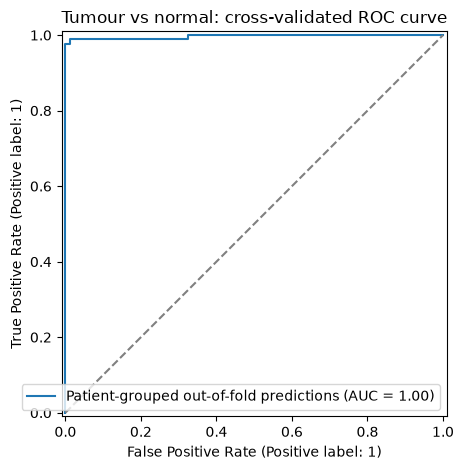


Final model C: 0.01

Top 20 genes by absolute standardised coefficient:
   gene  coefficient  importance                      association
  PNLIP     0.020446    0.020446 Higher expression favours tumour
   LIPF     0.015239    0.015239 Higher expression favours tumour
   TFF2     0.011985    0.011985 Higher expression favours tumour
   GDF2     0.011983    0.011983 Higher expression favours tumour
    TNR     0.010968    0.010968 Higher expression favours tumour
  KCNE2     0.010528    0.010528 Higher expression favours tumour
   MUC6     0.010452    0.010452 Higher expression favours tumour
  DCHS2     0.010050    0.010050 Higher expression favours tumour
   HAO1    -0.009192    0.009192 Higher expression favours normal
  A4GNT     0.009105    0.009105 Higher expression favours tumour
PCDH11X     0.008872    0.008872 Higher expression favours tumour
  ACTC1     0.008734    0.008734 Higher expression favours tumour
 SPINK1     0.008531    0.008531 Higher expression favours tumour
  N

In [21]:
# Report predictions made only when each patient was held out.
pooled_auc = roc_auc_score(
    oof_predictions["actual"],
    oof_predictions["tumour_probability"]
)

print(f"Mean fold ROC AUC: {cv_results['Outer test AUC'].mean():.3f}")
print(f"Fold AUC standard deviation: {cv_results['Outer test AUC'].std():.3f}")
print(f"Pooled out-of-fold ROC AUC: {pooled_auc:.3f}")

RocCurveDisplay.from_predictions(
    oof_predictions["actual"],
    oof_predictions["tumour_probability"],
    name="Patient-grouped out-of-fold predictions"
)
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.title("Tumour vs normal: cross-validated ROC curve")
plt.tight_layout()
plt.show()

# Tune and fit the final model using all GSE40419 training samples.
# Its training score is not used as an estimate of performance.
final_search = GridSearchCV(
    estimator=pipeline,
    param_grid=parameter_grid,
    scoring="roc_auc",
    cv=inner_cv,
    n_jobs=1,
    refit=True
)
final_search.fit(X_train, y, groups=groups)
final_model = final_search.best_estimator_

print("\nFinal model C:", final_search.best_params_["classifier__C"])

# Coefficients refer to genes scaled using the training data.
coefficients = final_model.named_steps["classifier"].coef_[0]

important_genes = pd.DataFrame({
    "gene": X_train.columns,
    "coefficient": coefficients,
    "importance": np.abs(coefficients)
})

important_genes["association"] = "Higher expression favours normal"
important_genes.loc[
    important_genes["coefficient"] > 0, "association"
] = "Higher expression favours tumour"
important_genes.loc[
    important_genes["coefficient"] == 0, "association"
] = "Zero coefficient"

important_genes = important_genes.sort_values(
    "importance", ascending=False
)

print("\nTop 20 genes by absolute standardised coefficient:")
print(important_genes.head(20).to_string(index=False))

External test: GSE10072
---------------------------------------------
Samples: 107
Tumour samples: 58
Normal samples: 49
External ROC AUC (decision scores): 0.9933
Probabilities rounded to 0 or 1: 107
Predicted tumour samples: 107
Predicted normal samples: 0
Decision-score range: 65.46 to 78.19


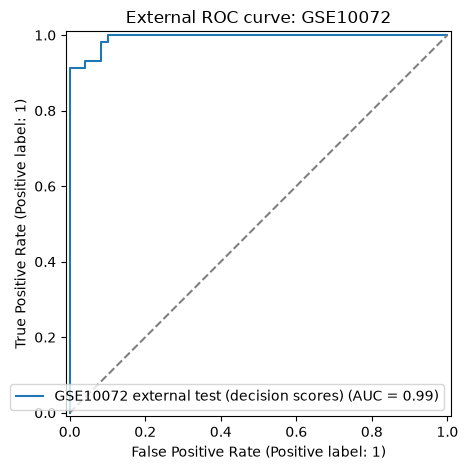

In [23]:
external_features = X_external.loc[:, X_train.columns]
external_labels = y_external.loc[external_features.index, "tumour"]

# ROC AUC needs ranking scores, not necessarily probabilities.
# Under platform shift, sigmoid probabilities can round to exactly 0 or 1.
external_scores = final_model.decision_function(external_features)
external_probabilities = final_model.predict_proba(external_features)[:, 1]
external_classes = final_model.predict(external_features)

external_auc = roc_auc_score(external_labels, external_scores)
external_predictions = pd.DataFrame({
    "actual": external_labels,
    "decision_score": external_scores,
    "tumour_probability": external_probabilities,
    "predicted_tumour": external_classes
}, index=external_features.index)

saturated = (external_probabilities == 0) | (external_probabilities == 1)

print("External test: GSE10072")
print("-" * 45)
print("Samples:", len(external_features))
print("Tumour samples:", int(external_labels.sum()))
print("Normal samples:", int((external_labels == 0).sum()))
print(f"External ROC AUC (decision scores): {external_auc:.4f}")
print("Probabilities rounded to 0 or 1:", int(saturated.sum()))
print("Predicted tumour samples:", int((external_classes == 1).sum()))
print("Predicted normal samples:", int((external_classes == 0).sum()))
print(f"Decision-score range: {external_scores.min():.2f} to {external_scores.max():.2f}")

RocCurveDisplay.from_predictions(
    external_labels,
    external_scores,
    name="GSE10072 external test (decision scores)"
)
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.title("External ROC curve: GSE10072")
plt.tight_layout()
plt.show()